
# ChestScan AI — Exploration des données

## 1. Objectif du notebook

Ce notebook permet de :
- Configurer et vérifier l'environnement d'exécution.
- Accéder au dataset avec KaggleHub.
- Explorer les classes NORMAL et PNEUMONIA.
- Analyser la distribution des images.
- Vérifier la qualité des fichiers.
- Visualiser des exemples de radiographies.

## 2. Environnement

- Python
- TensorFlow / Keras
- Google Colab avec GPU T4
- KaggleHub
- NumPy, Pandas, Matplotlib et Seaborn



## 1. Vérification de l'environnement d'exécution

L'objectif est de vérifier la version de Python,
la version de TensorFlow et la disponibilité du GPU.


In [1]:

import sys
import os
import platform
import tensorflow as tf

print("Version de Python :", sys.version)
print("Exécutable Python :", sys.executable)
print("Système d'exploitation :", platform.platform())
print("Répertoire courant :", os.getcwd())
print("Version de TensorFlow :", tf.__version__)
print("GPU disponibles :", tf.config.list_physical_devices("GPU"))


Version de Python : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Exécutable Python : /usr/bin/python3
Système d'exploitation : Linux-6.6.122+-x86_64-with-glibc2.39
Répertoire courant : /content
Version de TensorFlow : 2.21.0
GPU disponibles : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]



## 2. Importation des bibliothèques

Nous importons les bibliothèques nécessaires à l'exploration,
à l'analyse statistique et à la visualisation du dataset.


In [2]:

from pathlib import Path
from collections import Counter
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

print("Toutes les bibliothèques ont ete importees avec succes.")


Toutes les bibliothèques ont ete importees avec succes.



## 3. Accès au dataset avec KaggleHub

Nous utilisons KaggleHub pour récupérer le dataset
Chest X-Ray Images (Pneumonia) depuis Kaggle.


In [3]:

%pip install -q kagglehub


In [4]:

import kagglehub

DATASET_ID = "paultimothymooney/chest-xray-pneumonia"

dataset_path = kagglehub.dataset_download(DATASET_ID)

print("Dataset telecharger.")


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset telecharger.


In [5]:

from pathlib import Path

dataset_root = Path(dataset_path)

print("Racine du dataset  :", dataset_root)
print("\nContenu du dossier :")

for item in sorted(dataset_root.iterdir()):
    kind = "Dossier" if item.is_dir() else "Fichier"
    print(f"{kind} : {item.name}")


Racine du dataset  : /kaggle/input/chest-xray-pneumonia

Contenu du dossier :
Dossier : chest_xray



## 4. Exploration de la structure du dataset

Nous explorons les sous-dossiers du dataset afin
d'identifier les ensembles train, validation et test,
ainsi que les classes NORMAL et PNEUMONIA.


In [6]:

from pathlib import Path

dataset_root = Path(dataset_path) / "chest_xray"

print("Chemin du dataset :", dataset_root)
print("Le dossier existe :", dataset_root.exists())

for item in sorted(dataset_root.iterdir()):
    if item.is_dir():
        print(f"\nDossier : {item.name}")

        for subitem in sorted(item.iterdir()):
            if subitem.is_dir():
                print(f"  Sous-dossier : {subitem.name}")


Chemin du dataset : /kaggle/input/chest-xray-pneumonia/chest_xray
Le dossier existe : True

Dossier : __MACOSX
  Sous-dossier : chest_xray

Dossier : chest_xray
  Sous-dossier : test
  Sous-dossier : train
  Sous-dossier : val

Dossier : test
  Sous-dossier : NORMAL
  Sous-dossier : PNEUMONIA

Dossier : train
  Sous-dossier : NORMAL
  Sous-dossier : PNEUMONIA

Dossier : val
  Sous-dossier : NORMAL
  Sous-dossier : PNEUMONIA



## 5. Analyse de la distribution des classes

Nous comptons les images disponibles dans chaque classe
pour les ensembles d'entraînement, de validation et de test.
Le dossier __MACOSX est ignoré car il ne contient pas
les données utiles à notre classification.


In [7]:

from pathlib import Path

# Dossier contenant les ensembles train, val et test
DATASET_ROOT = Path(dataset_path) / "chest_xray" / "chest_xray"

# Extensions d'images accepter 
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# verification du chemin
assert DATASET_ROOT.exists(), (
    f"Le dossier est introuvable : {DATASET_ROOT}"
)

print("Dataset utilisé :", DATASET_ROOT)

for split in ["train", "val", "test"]:
    split_path = DATASET_ROOT / split
    print(f"{split} existe :", split_path.exists())


Dataset utilisé : /kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray
train existe : True
val existe : True
test existe : True


In [8]:

records = []

for split in ["train", "val", "test"]:
    for class_name in ["NORMAL", "PNEUMONIA"]:

        class_path = DATASET_ROOT / split / class_name

        if not class_path.exists():
            print(f"Attention : dossier absent : {class_path}")
            continue

        images = [
            path for path in class_path.iterdir()
            if path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        ]

        records.append({
            "split": split,
            "class": class_name,
            "n_images": len(images)
        })

df_distribution = pd.DataFrame(records)

display(
    df_distribution.pivot(
        index="split",
        columns="class",
        values="n_images"
    ).fillna(0).astype(int)
)

print("\nNombre total d'images :",
      df_distribution["n_images"].sum())


class,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8



Nombre total d'images : 5856


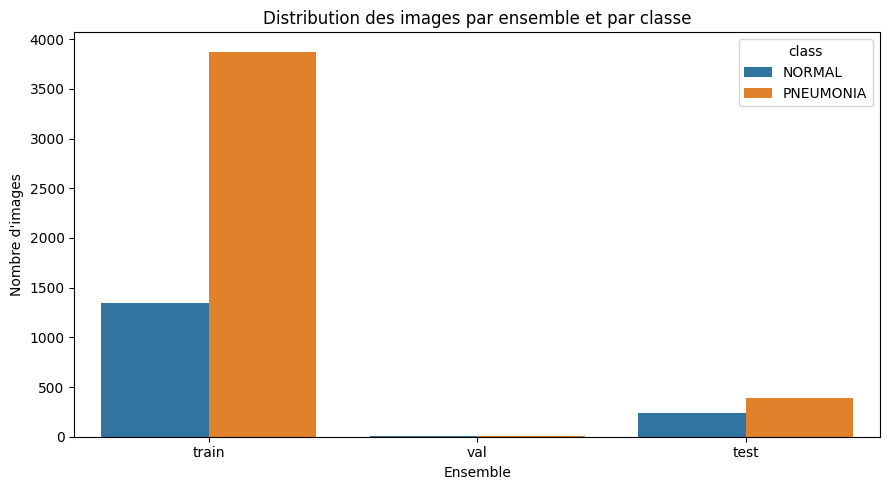

In [9]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_distribution,
    x="split",
    y="n_images",
    hue="class"
)

plt.title("Distribution des images par ensemble et par classe")
plt.xlabel("Ensemble")
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.show()



## 6. Visualisation images



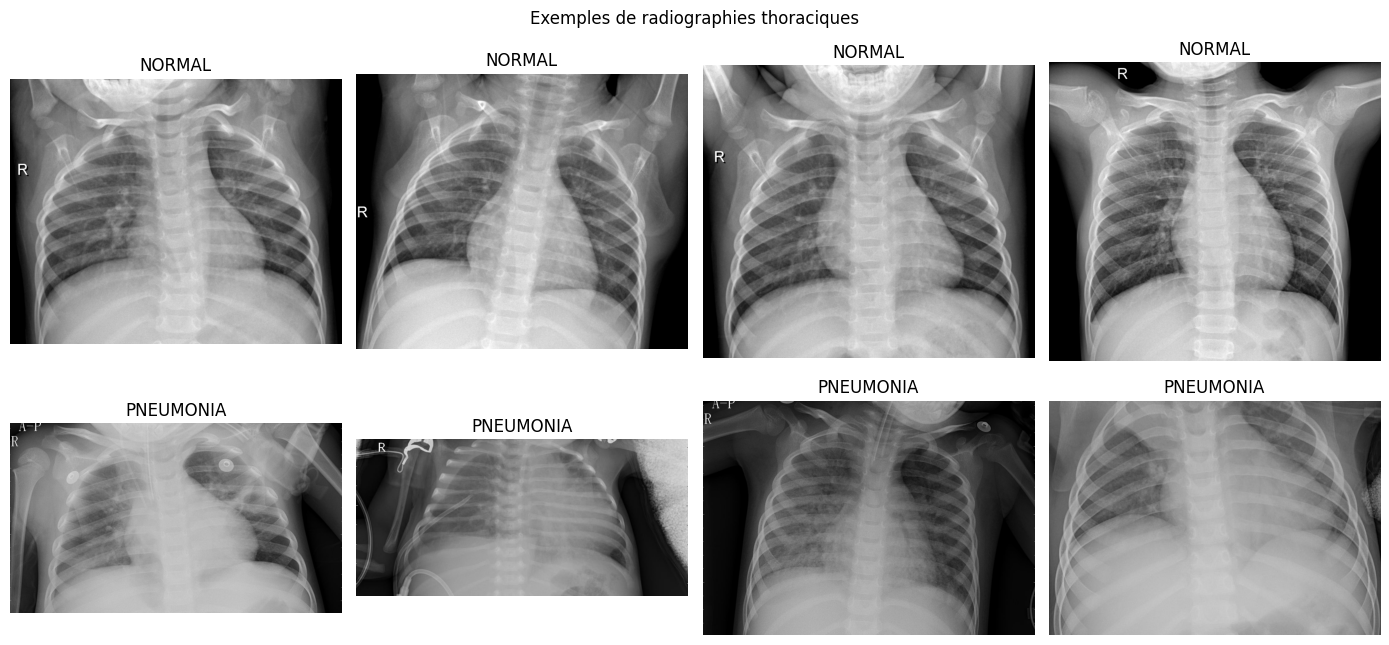

In [10]:

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(["NORMAL", "PNEUMONIA"]):
    class_path = DATASET_ROOT / "train" / class_name

    image_paths = [
        p for p in class_path.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected_paths = random.sample(
        image_paths,
        k=min(4, len(image_paths))
    )

    for col, image_path in enumerate(selected_paths):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

    for col in range(len(selected_paths), 4):
        axes[row, col].axis("off")

plt.suptitle("Exemples de radiographies thoraciques")
plt.tight_layout()
plt.show()



## 7. Vérification de l'intégrité des images

Nous vérifions que les fichiers image du dataset
peuvent être ouverts et décodés correctement.


In [11]:

corrupted_images = []
valid_images = 0

for split in ["train", "val", "test"]:
    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_path = DATASET_ROOT / split / class_name

        for image_path in class_path.iterdir():
            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            try:
                with Image.open(image_path) as img:
                    img.verify()

                valid_images += 1

            except Exception as error:
                corrupted_images.append({
                    "path": str(image_path),
                    "error": str(error)
                })

print("Images valides :", valid_images)
print("Images illisibles :", len(corrupted_images))

if corrupted_images:
    display(pd.DataFrame(corrupted_images).head(10))


Images valides : 5856
Images illisibles : 0



## 8. Conclusions de l'exploration des données

- Le dataset contient 5 856 images réparties entre NORMAL et PNEUMONIA.
- Les images sont organisées en trois ensembles : train, val et test.
- Le dossier train contient 5 216 images.
- Le dossier val contient seulement 16 images, ce qui est insuffisant pour une validation fiable.
- Le dossier test contient 624 images et doit rester indépendant de l'entraînement.
- La classe PNEUMONIA est majoritaire dans l'ensemble train.
- Aucune image illisible n'a été détectée lors de la vérification.

### Décisions à prendre

- Recréer un ensemble de validation à partir des données train.
- Conserver l'ensemble test sans modification pour l'évaluation finale.
- Étudier le déséquilibre des classes.
- Préparer les images avec un prétraitement cohérent.



## 9. Préparation des chemins et des labels

Nous créons un tableau contenant le chemin de chaque image
et sa classe. Nous préparons ensuite une séparation
stratifiée entre entraînement et validation.


In [12]:

records = []

for split in ["train", "test"]:
    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_path = DATASET_ROOT / split / class_name

        for image_path in class_path.iterdir():
            if (
                image_path.is_file()
                and image_path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                records.append({
                    "path": str(image_path),
                    "label": class_name,
                    "split": split
                })

df_images = pd.DataFrame(records)

print("Nombre total d'images :", len(df_images))
display(df_images.head())
print("\nRépartition :")
display(pd.crosstab(df_images["split"], df_images["label"]))


Nombre total d'images : 5840


,path,label,split
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train



Répartition :


label,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875


In [13]:

from sklearn.model_selection import train_test_split

df_train = df_images[df_images["split"] == "train"].copy()
df_test = df_images[df_images["split"] == "test"].copy()

train_df, val_df = train_test_split(
    df_train,
    test_size=0.20,
    random_state=42,
    stratify=df_train["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = df_test.reset_index(drop=True)

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))

print("\nRepartition de train :")
display(train_df["label"].value_counts())
    
print("\nRepartition de validation :")
display(val_df["label"].value_counts())

print("\nRépartition de test :")
display(test_df["label"].value_counts())


Train : 4172
Validation : 1044
Test : 624

Repartition de train :


,count
label,
PNEUMONIA,3099
NORMAL,1073



Repartition de validation :


,count
label,
PNEUMONIA,776
NORMAL,268



Répartition de test :


,count
label,
PNEUMONIA,390
NORMAL,234
